# 🚕 Q-Learning en Taxi-v4 — Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [1]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation


## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [2]:
env = gym.make("Taxi-v4", render_mode="rgb_array")

print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)


Número de estados: 500
Número de acciones: 6


### Pregunta 1

¿Cuántos estados y cuántas acciones tiene Taxi-v4?

Taxi-v4 tiene 500 estados y 6 acciones posibles. Tiene muchos más estados que FrozenLake porque cada estado de Taxi debe representar simultáneamente la posición del taxi (25 posiciones posibles), la ubicación del pasajero (5 posibilidades, incluidas las situaciones en las que ya está dentro del taxi) y el destino (4 posibilidades). Por tanto, el espacio de estados es 25 × 5 × 4 = 500.

Explique brevemente por qué Taxi tiene muchos más estados que FrozenLake.

En FrozenLake, el estado suele representar únicamente la posición del agente dentro de una cuadrícula mucho más sencilla.

## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [3]:
state, info = env.reset(seed=42)

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)


Estado: 386
Acción: 3
Nuevo estado: 366
Recompensa: -1
Terminated: False


### Pregunta 2

En la interacción anterior identifique:

$$
s_t,\quad a_t,\quad r_{t+1},\quad s_{t+1}
$$

¿Qué representa cada elemento?

En la interacción registrada se observa:
- Estado actual, s_t = 386: representa la situación del ambiente antes de ejecutar la acción; incluye la posición del taxi, la ubicación del pasajero y su destino, codificados en un único entero.
- Acción, a_t = 3: corresponde a moverse hacia el oeste (West).
- Recompensa, r_{t+1} = -1: es la recompensa inmediata recibida después de ejecutar la acción. En este caso, es el costo habitual de realizar un movimiento.
- Estado siguiente, s_{t+1} = 366: representa la nueva situación del ambiente después de ejecutar la acción hacia el oeste.

La transición observada puede expresarse como (386, 3, -1, 366). El indicador Terminated = False significa que el episodio no terminó con esa acción.


## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [4]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]


Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3

¿Cuántos valores debe aprender el agente en total?

Calcule:

$$
|\mathcal{S}| \times |\mathcal{A}|
$$

El agente debe aprender 500 × 6 = 3000 valores Q. Cada valor corresponde a una combinación de estado y acción, Q(s,a), y estima el retorno futuro descontado esperado al ejecutar esa acción en ese estado y continuar después siguiendo una política óptima.

## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [5]:
def choose_action(Q, state, epsilon, env):
    if random.uniform(0, 1) < epsilon:
        return env.action_space.sample()  # Acción aleatoria
    else:
        return np.argmax(Q[state])  # Acción con el mayor valor Q


## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [6]:
def update_q(Q, state, action, reward, next_state, alpha, gamma):
    '''Calcular el target
    Calcular el error TD
    Actualizar Q[state, action]'''
    target = reward + gamma * np.max(Q[next_state])
    error = target - Q[state, action]
    Q[state, action] += alpha * error


## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [7]:
def train_q_learning(
    env,
    Q,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
):
    rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps):

            # TODO 1: escoger acción
            action = choose_action(Q, state, epsilon, env)

            # TODO 2: ejecutar acción en el ambiente
            # next_state, reward, terminated, truncated, _ = ...
            next_state, reward, terminated, truncated, _ = env.step(action)

            # TODO 3: actualizar Q
            # update_q(...)
            update_q(Q, state, action, reward, next_state, alpha, gamma)

            # TODO 4: actualizar estado y recompensa acumulada
            state = next_state
            total_reward += reward

            # TODO 5: terminar si corresponde
            if terminated or truncated:
                break

        rewards.append(total_reward)

    return Q, rewards


## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [8]:
Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)


## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


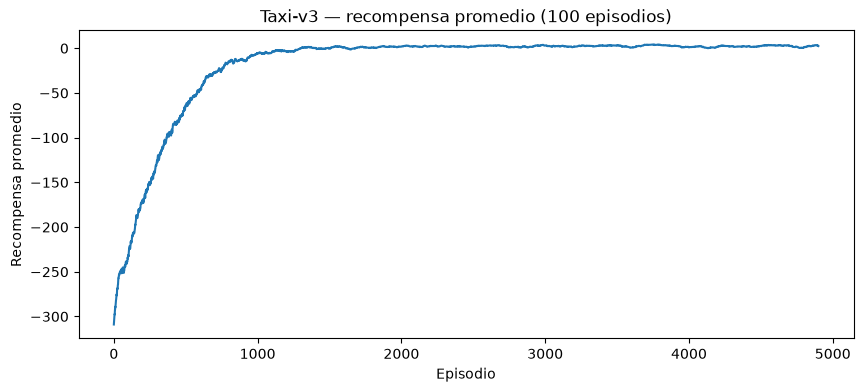

In [9]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi-v3 — recompensa promedio ({window} episodios)")
plt.show()


### Pregunta 4

Describa la curva de aprendizaje.

- ¿La recompensa promedio mejora?
- ¿Después de aproximadamente cuántos episodios comienza a estabilizarse?
- ¿El comportamiento observado indica convergencia perfecta o solamente una política razonablemente buena?

La curva representa una media móvil de la recompensa de los últimos 100 episodios, por lo que suaviza las variaciones de episodios individuales. En general, una mejora de la recompensa promedio indica que el agente aprende a completar la tarea con menos movimientos y menos acciones incorrectas. La curva debe interpretarse como una tendencia de aprendizaje, no como evidencia suficiente de convergencia matemática exacta.

La versión del notebook consultada contiene la gráfica como imagen, pero no registra numéricamente el episodio exacto en el que se estabiliza. Por rigor, no conviene afirmar un número preciso sin observar la gráfica directamente. La respuesta puede formularse así: “La recompensa promedio mejora durante el entrenamiento y posteriormente muestra una tendencia a estabilizarse, aunque persisten fluctuaciones. Esto indica que el agente aprende una política razonablemente buena, pero no demuestra una convergencia perfecta, ya que la exploración y la variabilidad de los episodios pueden seguir afectando las recompensas.”

## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [10]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward


def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [11]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)


Recompensa total sin entrenamiento: -167


Ahora observe el agente entrenado.


In [12]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)


Recompensa total después del entrenamiento: 10


### Pregunta 5

Compare los dos episodios.

- ¿Qué diferencias observa en el comportamiento del taxi?
- ¿El taxi sin entrenamiento logra completar la tarea?
- ¿El agente entrenado evita acciones innecesarias?
- ¿Qué evidencia visual le permite afirmar que el agente aprendió?

El taxi sin entrenamiento obtiene una recompensa total de -167, mientras que el episodio reproducido después del entrenamiento obtiene una recompensa total de 10. La diferencia es de 177 puntos a favor del agente entrenado. Con la tabla Q inicializada en cero, la selección greedy no dispone de conocimiento útil y, ante valores empatados, la función de selección puede escoger acciones que produzcan movimientos poco eficientes o repetitivos. En cambio, el agente entrenado utiliza los valores Q aprendidos para escoger acciones que favorecen la recogida y entrega del pasajero.

En el episodio inicial no se completa la tarea de forma eficiente dentro del límite de pasos empleado. El agente entrenado muestra un comportamiento más dirigido a la meta y evita buena parte de las acciones innecesarias. La evidencia es la comparación visual de las trayectorias y, cuantitativamente, la mejora de la recompensa total de -167 a 10. Esta comparación demuestra aprendizaje en ese episodio concreto; para medir el rendimiento general con más rigor sería conveniente evaluar varios episodios con distintas semillas y comparar la recompensa promedio y la tasa de éxito.

## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [13]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))


Estado: 123
Q-values: [-3.15055442 -3.25366036 -1.81880289  3.94947757 -5.19831156 -4.90957228]
Mejor acción: 3


### Pregunta 6

Para el estado seleccionado:

1. ¿Cuál es la acción con mayor valor Q?
2. ¿Qué significa que una acción tenga un valor Q mayor que otra?
3. ¿Por qué no podemos interpretar $Q(s,a)$ únicamente como la recompensa inmediata de ejecutar la acción?

Para el estado 123, los valores Q son aproximadamente:
- South (acción 0): -3.151
- North (acción 1): -3.254
- East (acción 2): -1.819
- West (acción 3): 3.949
- Pickup (acción 4): -5.198
- Dropoff (acción 5): -4.910

1. La acción con mayor valor Q es la acción 3, moverse hacia el oeste (West), con Q(123, 3) ≈ 3.949.

2. Que una acción tenga un valor Q mayor significa que, según la experiencia aprendida por el agente, esa acción ofrece un retorno acumulado descontado esperado más favorable que las alternativas desde el estado actual. En este estado, moverse al oeste es la opción preferida entre las seis acciones disponibles.

3. Q(s,a) no representa únicamente la recompensa inmediata. Incluye la recompensa obtenida al ejecutar la acción y una estimación de las recompensas futuras descontadas que se pueden obtener desde el siguiente estado. Por eso una acción con recompensa inmediata baja o negativa puede tener un valor Q alto si conduce a estados desde los cuales es probable completar la tarea de forma eficiente.

## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar:

- $\alpha$
- $\gamma$
- $\epsilon$

### Pregunta 7

Compare el nuevo entrenamiento con el original.

Explique cómo el cambio del hiperparámetro afectó:

- velocidad de aprendizaje,
- estabilidad,
- recompensa final,
- comportamiento observado.

OBSERVACIÓN DE RIGOR: en la versión del notebook de GitHub consultada aparecen los resultados del entrenamiento original, pero no se observa un segundo entrenamiento con un hiperparámetro modificado ni sus resultados. Por tanto, no es correcto inventar una recompensa final o afirmar que la curva efectivamente mejoró o empeoró en el experimento. La siguiente explicación conceptual debe ajustarse al hiperparámetro que realmente se haya cambiado y a los resultados de esa ejecución.

Si se modificó alpha (tasa de aprendizaje), un alpha mayor hace que cada actualización incorpore una proporción mayor del nuevo error temporal (TD), lo que puede acelerar el aprendizaje inicial, pero también generar actualizaciones más variables o inestables. Un alpha menor produce cambios más graduales y puede estabilizar las actualizaciones, aunque el aprendizaje puede ser más lento. El efecto concreto en la recompensa final debe comprobarse comparando ambas curvas y evaluando episodios bajo condiciones equivalentes.

Si se modificó gamma (factor de descuento), un gamma mayor da más peso a las recompensas futuras, lo cual es importante en Taxi porque el agente debe planear una secuencia de movimientos, recoger al pasajero y llevarlo al destino. Un gamma menor enfatiza relativamente más las recompensas inmediatas y puede hacer que el agente valore menos las consecuencias a largo plazo. El resultado concreto en velocidad, estabilidad y recompensa no puede determinarse sin ejecutar y comparar el experimento.

Si se modificó epsilon (probabilidad de exploración), un epsilon mayor aumenta la frecuencia de acciones aleatorias. Esto puede ayudar a descubrir rutas y acciones útiles, especialmente al principio, pero también puede reducir la recompensa durante la evaluación si se mantiene alto. Un epsilon menor hace que el agente aproveche más lo aprendido, pero una exploración insuficiente puede impedir descubrir mejores alternativas. El efecto real debe comprobarse con la curva de aprendizaje y con episodios de evaluación.

Para redactar la comparación final de manera rigurosa, se deben indicar el hiperparámetro modificado, su valor original y su nuevo valor, y comparar la recompensa promedio (idealmente sobre varios episodios), la forma de la curva y el comportamiento visual. Una sola recompensa de un solo episodio no basta para concluir que un hiperparámetro es superior.


## Entrega

El notebook debe contener:

1. implementación de `choose_action`;
2. implementación de `update_q`;
3. implementación de `train_q_learning`;
4. curva de aprendizaje;
5. visualización del agente antes y después del entrenamiento;
6. respuestas a las siete preguntas.

No es necesario modificar las funciones auxiliares de visualización.
